# 1. Data and the definition of default

**Question of the project:** why did mortgages originated in 2006 default so much more than those originated in 2017, and how much of the difference is the *borrowers* versus the *environment* they lived through?

**Data:** Freddie Mac's Single-Family Loan-Level Dataset, sample files: a simple random sample of 50,000 thirty-year fixed-rate loans per origination year, each followed month by month until it is paid off, defaults or the data end (June 2026).

> The raw files are not in this repository: Freddie Mac's terms allow publishing research results but not the data. Every table and chart below is an aggregate; no individual loan is shown. To reproduce, download the sample files after a free registration and set `FREDDIE_DIR`.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk.data import load_loans, monthly_new_dlq90

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY = "#1a73e8", "#d93025", "#80868b"

loans = load_loans((2006, 2017))          # one row per loan, built with SQL (DuckDB)
loans.shape

(100000, 28)

## The two portfolios at origination

On paper, 2006 borrowers look somewhat riskier but not alarming: three times as many have a credit score below 660 and more of them took cash out of their home, yet their average loan-to-value ratio is *lower* and their debt-to-income ratio similar. Notebook 3 measures how much of the default gap these differences explain.

In [2]:
def share(s, value):
    return (s == value).mean()

profile = loans.groupby("vintage").agg(
    loans=("loan_id", "size"),
    fico=("fico", "mean"),
    ltv=("ltv", "mean"),
    dti=("dti", "mean"),
    rate=("rate", "mean"),
    investor=("occupancy", lambda s: share(s, "I")),
    cash_out_refi=("purpose", lambda s: share(s, "C")),
    first_time_buyer=("first_time_buyer", lambda s: share(s, "Y")),
    fico_below_660=("fico", lambda s: (s < 660).mean()),
).T
profile

vintage,2006,2017
loans,50000,50000
fico,723.563,744.731
ltv,69.961,74.983
dti,36.516,35.145
rate,6.403,4.192
investor,0.046,0.097
cash_out_refi,0.373,0.228
first_time_buyer,0.106,0.215
fico_below_660,0.154,0.051


## How each loan ended

Each loan ends in one of three ways: it **defaults**, it is **prepaid** (sold, refinanced or paid off), or it is still running when the data end (**censored**). Prepayment matters: a loan that has been refinanced can no longer default. That is a *competing risk*, handled in notebook 2.

In [3]:
outcome = (loans.assign(outcome=loans["event"].map({0: "censored", 1: "default", 2: "prepaid"}))
                .groupby(["vintage", "outcome"]).size().unstack())
outcome.assign(default_rate=outcome["default"] / outcome.sum(axis=1))

outcome,censored,default,prepaid,default_rate
vintage,,,,
2006,845,7142,42013,0.143
2017,11626,1254,37120,0.025


## Trap 1: in 2020, "90 days late" did not mean default

The standard definition of default (Basel, IFRS 9) is **90 or more days past due**. Applied blindly, the 2017 vintage would show many more defaults than it really had: in 2020, millions of US borrowers entered COVID-19 **forbearance**, a legal pause in payments. Their loans were reported as delinquent while the plan lasted, but most of them were never in credit trouble.

The dataset flags, month by month, whether a loan is in a forbearance plan or has a disaster-related delinquency. Counting the first 90+ delinquency of each 2017 loan by calendar month:

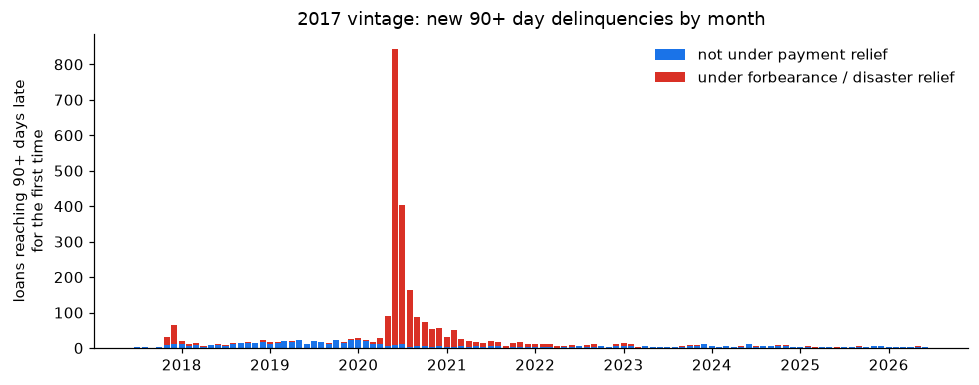

,not under relief,under relief
year,,
2017,27,76
2018,123,36
2019,203,27
2020,111,1750
2021,48,198
2022,45,57
2023,57,23
2024,63,13
2025,42,7


In [4]:
monthly = monthly_new_dlq90(2017)
wide = monthly.pivot_table(index="month", columns="relief", values="new_dlq90", aggfunc="sum").fillna(0)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(wide.index, wide.get(False, 0), width=25, color=BLUE, label="not under payment relief")
ax.bar(wide.index, wide.get(True, 0), width=25, bottom=wide.get(False, 0), color=RED, label="under forbearance / disaster relief")
ax.set_ylabel("loans reaching 90+ days late\nfor the first time")
ax.set_title("2017 vintage: new 90+ day delinquencies by month")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("../figures/forbearance_spike.png", bbox_inches="tight")
plt.show()

yearly = monthly.assign(year=monthly["month"].dt.year).pivot_table(index="year", columns="relief", values="new_dlq90", aggfunc="sum").fillna(0).astype(int)
yearly.columns = ["not under relief", "under relief"]
yearly

The 2020 spike is almost entirely forbearance. There is also a smaller cluster of relief delinquencies at the end of 2017. The data only flag them as *disaster-related*; they do not say which disaster. Where were those loans?

In [5]:
from credit_risk.data import relief_dlq90_by_state
by_state = relief_dlq90_by_state(2017, before=201901)
print("loans reaching 90+ days late under relief in 2017-2018:", by_state["relief_dlq90"].sum())
by_state.head(5)

loans reaching 90+ days late under relief in 2017-2018: 122


,state,relief_dlq90,loans,share_of_relief_dlq90,share_of_portfolio
0,FL,77,3402,0.631,0.068
1,TX,29,3798,0.238,0.076
2,CA,4,6478,0.033,0.130
3,GA,2,1557,0.016,0.031
4,WY,1,89,0.008,0.002


Florida and Texas hold most of them, far more than their share of the portfolio, and they appear in November–December 2017, about 90 days after hurricanes Harvey (Texas, August 2017) and Irma (Florida, September 2017). The pattern is consistent with those storms; the dataset itself does not name the cause.

What happened to all the loans whose first 90+ delinquency was under relief decides whether they should count as defaults:

In [6]:
relief_first = loans[(loans["vintage"] == 2017) & loans["t_relief90"].notna()]
after = pd.Series({
    "loans whose first 90+ delinquency was under relief": len(relief_first),
    "later defaulted outside relief, or had a credit event": relief_first["t_default_adj"].notna().sum(),
    "later prepaid without defaulting": ((relief_first["event"] == 2)).sum(),
    "still active and never defaulted": ((relief_first["event"] == 0)).sum(),
})
after

loans whose first 90+ delinquency was under relief       2401
later defaulted outside relief, or had a credit event     728
later prepaid without defaulting                          957
still active and never defaulted                          716
dtype: int64

In [7]:
naive = loans.groupby("vintage")["t_default_any"].apply(lambda s: s.notna().mean())
adjusted = loans.groupby("vintage")["t_default_adj"].apply(lambda s: s.notna().mean())
definitions = pd.DataFrame({"90+ days late (naive)": naive, "excluding payment relief": adjusted})
definitions.assign(overstatement=definitions.iloc[:, 0] / definitions.iloc[:, 1])

,90+ days late (naive),excluding payment relief,overstatement
vintage,,,
2006,0.144,0.143,1.010
2017,0.059,0.025,2.334


**Decision:** a loan defaults the first month it is 90+ days late *while not under a payment-relief plan*, or when it has a credit event (short sale, charge-off, foreclosure sale). The naive definition would more than double the 2017 default rate, and any model trained on it would learn that "2020 borrowers were risky" when what happened was a policy.

## Loss given default

For defaulted loans with a credit event, the dataset reports the realised loss after selling the property and recovering mortgage insurance. Many loans that reach 90+ days late later **cure** (catch up or refinance) and lose nothing, so the loss rate per defaulted dollar is computed over all defaults, with cures at zero loss.

In [8]:
d = loans[loans["event"] == 1].copy()
d["loss"] = d["actual_loss"].where(d["zbc"].isin(["02", "03", "09"]), 0).fillna(0)
lgd = d.groupby("vintage").apply(lambda g: pd.Series({
    "defaults": len(g),
    "share_ending_in_credit_event": g["zbc"].isin(["02", "03", "09"]).mean(),
    "loss_given_default": g["loss"].sum() / g["upb_default"].sum(),
}), include_groups=False)
lgd

,defaults,share_ending_in_credit_event,loss_given_default
vintage,,,
2006,7142.0,0.537,0.266
2017,1254.0,0.061,0.007


In [9]:
summary = pd.concat([profile.T, definitions, lgd], axis=1)
summary.to_csv("../results/vintage_summary.csv")